In [9]:
from typing import Annotated

from dotenv import load_dotenv

load_dotenv()

from langchain.chat_models import init_chat_model
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict


In [10]:
import os

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

`Annotated[list, add_messages]` attaches extra metadata to the type. Here, `add_messages` is a **reducer**: it tells LangGraph *how to merge* a node's output into the existing value of `messages`.

**Without it**, LangGraph's default is to **overwrite** the key. Each node's return replaces the old list.

**With it**, new messages are **appended** (and merged by ID if a message with the same ID exists).

**Example:**

```python
# Current state
{"messages": [HumanMessage("Hi")]}

# A node returns
{"messages": [AIMessage("Hello!")]}
```

| Setup | Resulting `messages` |
|---|---|
| `list` | `[AIMessage("Hello!")]` (history lost) |
| `Annotated[list, add_messages]` | `[HumanMessage("Hi"), AIMessage("Hello!")]` |

**Why use it:** chat history needs to accumulate across nodes, so nodes can return just the *new* message instead of copying the whole list each time.

In [13]:
llm = init_chat_model("groq:qwen/qwen3.8-27b")

class State(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: State) -> State:
    response = llm.invoke(state["messages"])  # 1. call the LLM with the history
    return {"messages": [response]}           # 2. return only the new message

builder = StateGraph(State)
builder.add_node("chatbot_node", chatbot)

builder.add_edge(START, "chatbot_node")
builder.add_edge("chatbot_node", END)

graph = builder.compile()

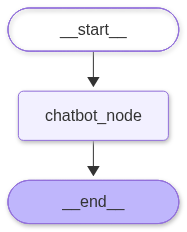

In [15]:
graph

In [17]:
message = {"role": "user", "content": "Who wrote the play 'Romeo and Juliet'? Print only the name"}
# message = {"role": "user", "content": "What was my last question?"}
# message = {"role": "user", "content": "What is the latest price of MSFT stock?"}
response = graph.invoke({"messages":[message]})

response["messages"]

[HumanMessage(content="Who wrote the play 'Romeo and Juliet'? Print only the name", additional_kwargs={}, response_metadata={}, id='6dba441b-04f1-4ff0-b71e-29d10db66654'),
 AIMessage(content='William Shakespeare', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 3, 'prompt_tokens': 27, 'total_tokens': 30, 'completion_time': 0.025248297, 'completion_tokens_details': None, 'prompt_time': 3.01e-05, 'prompt_tokens_details': None, 'queue_time': 0.059712239, 'total_time': 0.025278397}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_3f7cb2e2dd', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a221fc-2d97-726a-bcc5-dc47a37bea65-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 27, 'output_tokens': 3, 'total_tokens': 30})]

## Flow

`graph.invoke({"messages": [message]})` → input goes to **`State`**, then to **`chatbot`** (via the node `"chatbot_node"`).

```
graph.invoke({"messages":[message]})
        │
        ▼
   State initialized  → state["messages"] = [HumanMessage(...)]
        │              (add_messages converts your dict to a HumanMessage)
        ▼
      START
        │
        ▼
 "chatbot_node"  ──► chatbot(state)
        │               ├─ llm.invoke(state["messages"])
        │               └─ returns {"messages": [AIMessage]}
        ▼
   add_messages reducer APPENDS AIMessage to state["messages"]
        │
        ▼
       END
        │
        ▼
 returns final state → {"messages": [HumanMessage, AIMessage]}
```

## Step by step

1. **Input → State**: your dict `{"messages": [message]}` becomes the initial `State`. The `add_messages` reducer normalizes `{"role": "user", ...}` into a `HumanMessage`.
2. **START → chatbot_node**: the edge routes the state to your node function `chatbot(state)`. `START` is just an entry marker, with no logic.
3. **Inside `chatbot`**: `state["messages"]` is the full history. `llm.invoke(...)` returns an `AIMessage`.
4. **Return value**: `{"messages": [response]}` is a *partial update*, not a replacement. The `add_messages` reducer **appends** it to the existing list.
5. **chatbot_node → END**: graph finishes and returns the final state.

## Final output

```python
response["messages"]
# [HumanMessage(content="Who wrote ... Print only the name"),
#  AIMessage(content="William Shakespeare")]
```

**Note:** for the MSFT price query, the LLM can't answer accurately because this graph has no tools or search. It will only answer from its training data (or say it can't).

**Each graph.invoke() starts with a fresh state, so nothing carries over to your second request.**

In [19]:
state = None
while True:
    in_message = input("Human >> ")
    if in_message.lower() in {"bye", "done"}:
        break
    if state is None:
        state: State = {
            "messages": [{"role": "user", "content": in_message}]
        }
    else:
        state["messages"].append({"role": "user", "content": in_message})

    state = graph.invoke(state)
    print("Assistant ::", state["messages"][-1].content)

Assistant :: I am Qwen, a large language model independently developed by Alibaba Group's Tongyi Lab. I am here to assist you with a wide range of tasks, including answering questions, writing, coding, logical reasoning, and creative expression.

How can I help you today?
Assistant :: Yes, I am familiar with **Groq**.

Groq is an AI infrastructure company known for developing the **Language Processing Unit (LPU)**, a specialized hardware architecture designed to run large language models (LLMs) with extremely high speed and low latency.

Key points about Groq:

1. **Hardware Focus**: Unlike many AI companies that focus primarily on software or model development, Groq built custom silicon (the LPU) to optimize the inference process of LLMs.
2. **Speed**: Groq’s platform is renowned for its exceptional token generation speed, often providing near-instantaneous responses compared to traditional GPU-based inference.
3. **Platform**: They offer a cloud-based inference API that allows develo

KeyboardInterrupt: Interrupted by user

### 🤔 Before you move on
This chatbot can only answer from what the model already knows — it has no way to look up something real and current, like today's actual stock price. How would you give a graph node the ability to call an external function when it needs live data? That's `4_tool_call.ipynb`.